In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


# 03. Products and countries

## What this notebook does, in plain words

This notebook asks two simple questions. Where does the money come from, by country? And which products earn the most? Averages can hide concentration, so the notebook shows shares, not just totals.

## A note on POSTAGE and Manual

Two lines in the top product list are not gifts at all. POSTAGE is a delivery charge, and Manual is a manual entry. They are kept in the totals so the totals match the clean file, but they are flagged here so no one mistakes a delivery charge for a best selling gift.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams['figure.dpi'] = 120
ROOT = Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw' / 'online_retail.csv'
print('Charts folder:', CHARTS)
print('Data folder:', DATA)


Charts folder: /home/hatch/workspace/repo-builds/datanalytics-project/charts
Data folder: /home/hatch/workspace/repo-builds/datanalytics-project/data/processed


In [3]:
df = pd.read_csv(DATA / 'clean_transactions.csv', parse_dates=['InvoiceDate'])
country = df.groupby('Country').agg(revenue=('Revenue', 'sum'), orders=('InvoiceNo', 'nunique'), customers=('CustomerID', 'nunique')).reset_index().sort_values('revenue', ascending=False)
print(country.head(10).to_string(index=False))
print('United Kingdom share, percent:', round(country.loc[country['Country'] == 'United Kingdom', 'revenue'].iloc[0] / df['Revenue'].sum() * 100, 2))
print('Countries in clean file:', len(country))

       Country     revenue  orders  customers
United Kingdom 7308391.554   16646       3920
   Netherlands  285446.340      94          9
          EIRE  265545.900     260          3
       Germany  228867.140     457         94
        France  209024.050     389         87
     Australia  138521.310      57          9
         Spain   61577.110      90         30
   Switzerland   56443.950      51         21
       Belgium   41196.340      98         25
        Sweden   38378.330      36          8
United Kingdom share, percent: 82.01
Countries in clean file: 37


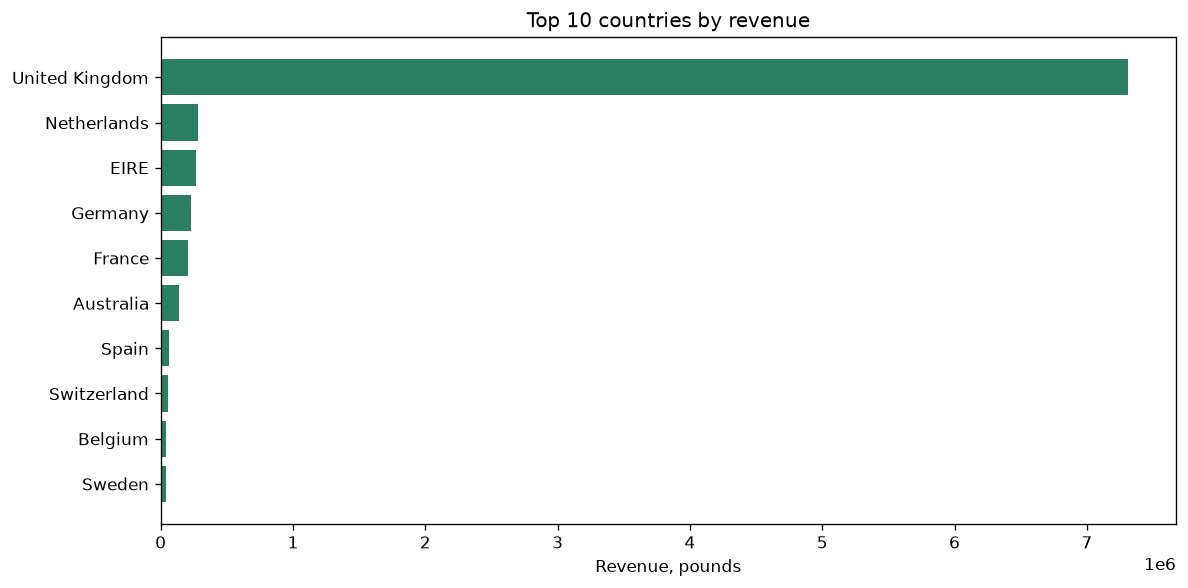

In [4]:
top10 = country.head(10)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10['Country'][::-1], top10['revenue'][::-1], color='#2a7f62')
ax.set_title('Top 10 countries by revenue')
ax.set_xlabel('Revenue, pounds')
plt.tight_layout()
plt.savefig(CHARTS / '07_country_revenue.png')
plt.show()

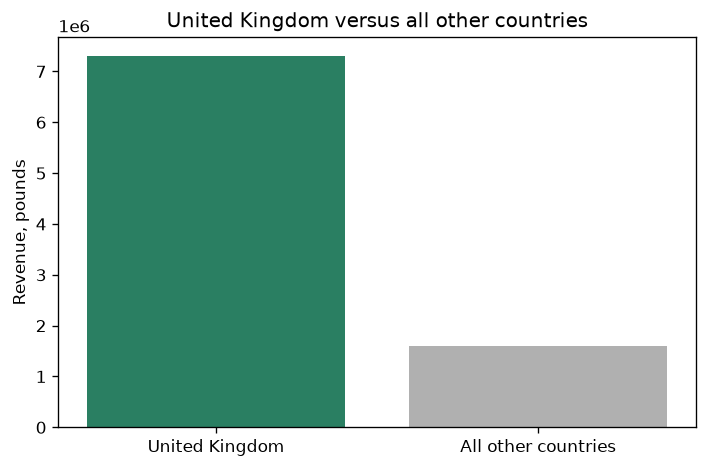

United Kingdom revenue: 7308391.55 Other countries: 1603016.35


In [5]:
uk = df[df['Country'] == 'United Kingdom']['Revenue'].sum()
rest = df['Revenue'].sum() - uk
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['United Kingdom', 'All other countries'], [uk, rest], color=['#2a7f62', '#b0b0b0'])
ax.set_title('United Kingdom versus all other countries')
ax.set_ylabel('Revenue, pounds')
plt.tight_layout()
plt.savefig(CHARTS / '08_uk_vs_rest.png')
plt.show()
print('United Kingdom revenue:', round(uk, 2), 'Other countries:', round(rest, 2))

                       Description   revenue  quantity
       PAPER CRAFT , LITTLE BIRDIE 168469.60     80995
          REGENCY CAKESTAND 3 TIER 142592.95     12402
WHITE HANGING HEART T-LIGHT HOLDER 100448.15     36725
           JUMBO BAG RED RETROSPOT  85220.78     46181
    MEDIUM CERAMIC TOP STORAGE JAR  81416.73     77916
                           POSTAGE  77803.96      3120
                     PARTY BUNTING  68844.33     15291
     ASSORTED COLOUR BIRD ORNAMENT  56580.34     35362
                            Manual  53779.93      7173
                RABBIT NIGHT LIGHT  51346.20     27202


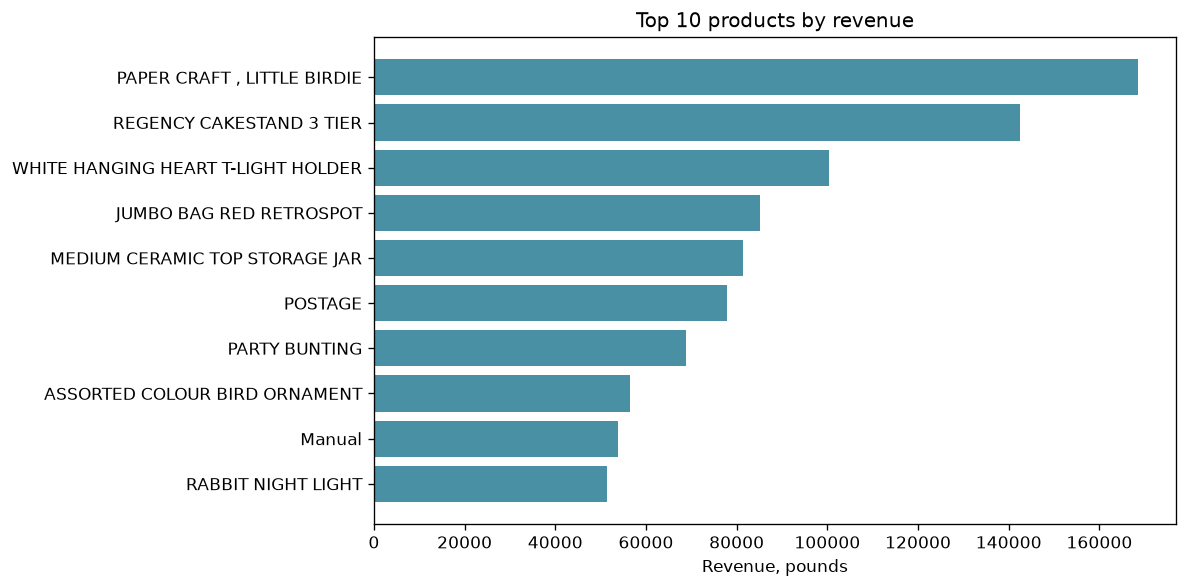

In [6]:
prod = df.groupby('Description').agg(revenue=('Revenue', 'sum'), quantity=('Quantity', 'sum')).reset_index().sort_values('revenue', ascending=False)
print(prod.head(10).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 5))
top = prod.head(10).iloc[::-1]
ax.barh(top['Description'], top['revenue'], color='#4a90a4')
ax.set_title('Top 10 products by revenue')
ax.set_xlabel('Revenue, pounds')
plt.tight_layout()
plt.savefig(CHARTS / '09_top_products.png')
plt.show()

## What we learned

The United Kingdom accounts for 7,308,391.55 pounds, or 82.01 percent of clean revenue. The next countries, Netherlands at 285,446.34 pounds and EIRE at 265,545.90 pounds, are far smaller. That concentration is a risk and a fact: growth outside the UK would need a different effort, and this shop, in this period, is mainly a UK shop. The top earning product line is PAPER CRAFT, LITTLE BIRDIE, at 168,469.60 pounds, followed by REGENCY CAKESTAND 3 TIER at 142,592.95 pounds. Both are gift and home lines, which fits the retailer description.

Next: notebook 04 groups customers by how recently, how often, and how much they buy.